# Cars

Plagarise the excellent tutorial here; 

https://altair-viz.github.io/altair-tutorial/notebooks/01-Cars-Demo.html

In [1]:
//> using dep io.github.quafadas::scautable-almond:0.0.46
//> using dep io.github.quafadas::dedav4s_notebook:0.10.8

import $cp.^.resources

import io.github.quafadas.table.*
import io.github.quafadas.scautable.notebook.{*, given}
import io.github.quafadas.plots.SetupVegaNotebook.{*, given}
import io.circe.syntax.*

In [2]:
val data = JsonTable.resource("cars.json").toVector.addColumn["YearInt", Int](_.Year.take(4).toInt)
data.display()

+-----+--------------+-----------+--------------+------------+------------------+---------------------------+--------+---------------+------------+---------+
|     | Acceleration | Cylinders | Displacement | Horsepower | Miles_per_Gallon | Name                      | Origin | Weight_in_lbs | Year       | YearInt |
+-----+--------------+-----------+--------------+------------+------------------+---------------------------+--------+---------------+------------+---------+
| 0   | 12.0         | 8         | 307.0        | Some(130)  | Some(18.0)       | chevrolet chevelle malibu | USA    | 3504          | 1970-01-01 | 1970    |
| 1   | 11.5         | 8         | 350.0        | Some(165)  | Some(15.0)       | buick skylark 320         | USA    | 3693          | 1970-01-01 | 1970    |
| 2   | 11.0         | 8         | 318.0        | Some(150)  | Some(18.0)       | plymouth satellite        | USA    | 3436          | 1970-01-01 | 1970    |
| 3   | 12.0         | 8         | 304.0        | Some(150)  | Some(16.0)       | amc rebel sst             | USA    | 3433          | 1970-01-01 | 1970    |
| 4   | 10.5         | 8         | 302.0        | Some(140)  | Some(17.0)       | ford torino               | USA    | 3449          | 1970-01-01 | 1970    |
| …   | …            | …         | …            | …          | …                | …                         | …      | …             | …          | …       |
| 401 | 15.6         | 4         | 140.0        | Some(86)   | Some(27.0)       | ford mustang gl           | USA    | 2790          | 1982-01-01 | 1982    |
| 402 | 24.6         | 4         | 97.0         | Some(52)   | Some(44.0)       | vw pickup                 | Europe | 2130          | 1982-01-01 | 1982    |
| 403 | 11.6         | 4         | 135.0        | Some(84)   | Some(32.0)       | dodge rampage             | USA    | 2295          | 1982-01-01 | 1982    |
| 404 | 18.6         | 4         | 120.0        | Some(79)   | Some(28.0)       | ford ranger               | USA    | 2625          | 1982-01-01 | 1982    |
| 405 | 19.4         | 4         | 119.0        | Some(82)   | Some(31.0)       | chevy s-10                | USA    | 2720          | 1982-01-01 | 1982    |
+-----+--------------+-----------+--------------+------------+------------------+---------------------------+--------+---------------+------------+---------+
… 396 more rows [406 rows × 10 columns]

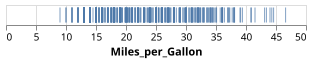

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoAIJgwmNZgBOCuNBQBGAEzcAwgE81JOue3IAHNwAicJQADmpyxgC2mEQSAOzcghBmlJhBENjmtuzcALJwppQA+kHmBQDi6mrWyDa+IABycpEo4IyYaGYQpoQABGCtaCam3eHqcABGpCDcAPJmiCTNAKoAyvpTINQiCGIFJAVqY14sAKxsACzcAJqYcmbNNgCcMWwAtGw2bzbr17cAktHVJ5sGQGIwmcyWKo2GwAOmOTlc7k8KFqAWCoQiUXEyBOXBACSSKTSGWqADZ4SBcvkiiVympKlBbBSGk1kCAJnAwABrbqULmuW48lh2NjrWbzRlslZrbibUSEXZQfaHVikh4sK43O5sx7PT6fb5a-7Y3XAzig4ymCzEKE2BFuKAeJIo-yBEJhTCRAEsGrxRLJVLpbU2U45PJaGlmMoVKG1FmYZohZzhChMXkKQZwQgJmZzBALKWrdZy7YKvYHI5nFikzW3e5A-XvQ1-AGmkEgQyWiE2yX2e1I50+V3oj1e7HsC74-1EoNMvFUiPFKN0hm2Gv1RoJtmNMDdMyYMYmXmUcS5iVLIuyrY7csqnFVjUgH7akCmxtfWtmY22IHtzvg60rF7Ng4X7R1kSHEA0XdTFvTYBwp0JQMSRsM553DQol2jekoTiDdWRAGBEjobpCESEgIDFPMCxAaVi2vMslQrVgzjOB5P3rPV3gNT9v0BZ4-zBK1IWAsCnS8VE3QxT0sRQM47HYxCA2JYMHlqBdMNpGNe2ZTdmiIswSIQdQ5AADywbpTlFM980lWjLw2BjFWVLwqzOO0ny1TjXm4pteNbX9zQ7ITuyAlBFJcB1xJdKCpNHWTkDOY5JwJZTZ2QOwRTDaksJXKFJ3jZo+jaDoum6OBwiCEyqPPQsZUc+VnOYxKTknZ9vPfZsvwCgSgv-YSexRUCQEigcJOHGCZIBVi8VSmcSTsENssXLScN7Aq9LZJMU1INMYFIMxnHKuA4Bq2yL3qksbyYu8qz7Ty6x1BtfI-B7upNQKLQAkTbDxUbwMHSSR1g7EkopObkO1TKKQ0yNsNXaoNoI1IiDgMJegUUYoCUGyaLoq9GtvVz5Ipdqnq4j4-Levi2z6kLAKqbxhv+6LIOg6Sx1YB5ZunSGf3QnLVoRpb8K3EAd26RoxjkShKDkOhEm6OgQjOvGHKuxiXNYbxQzejqXq6mnPuCrsGd7GJmcRAHXImjmEpsFhHwhlTbBF2Hcu0lAyHpbhCrZMAsw6KIlcoF5Fu6Kr6Rl1W7IAUQOiBinowmbqONhuY48mfMp17nyN3qvoGsLqlhCkWYgoHJs5nFded9KbHJZbNOXT3kG9tRfc2loSs6TAemKgZ6UwXpoEgA7KG6AAKShsAAShji7k9LJrbtQhCydfZ6c8NnqzUL0LbTEivbfi71jg8uuUOOR93aFqp287giDJIsi5igCAp5n+fcbs-GGuXomck2AsDal5LOnV-IfQLibb6g1qggTLlbVmlc7bem8E7XmLtqgxBhhhOGeVJQP1FomNQyZUyMHTNmekWZh7TzngvOqS9rpa0Sg3dcG83wG0gT+aB-UD69g8uXQGJ8Qaqh5khLBNgcFN3wa3IhftxbhF3PuQ8ahjw9Dod-EA4pzqMIJgA1O2tdYcK3jxamu9BKmx+vAo+wjYrAymuOdBfoJH12eDIj2a0mSPzFgrOgCBh59AqFEAJZheQ5m0dRX+6snKAJrqSR8JiKZmLzhYumVi4G1CEeNexVcEogPEWlFCpIBYrRbl4xGPiSFkN2hQgA5GAUg8hugFIYfZS6sTDE4hKYpJJ2cUlGjSfvM2MVskxXZqfcc8EXFFODGhDxd9CGkB9sQtkz9hhUEUFABA3QxgQFli0+CbS-4axXkcE4iSwGb2SVTVJUC94wKLlUB4lsorH1yag0GHAZnzWDLrW+5Tha6QIgPUqfdhi8ECbcSoxyYkpxYSwGIpIPJ9IgeY+5ljYHFxsH9JB7yJmiMSsccGmD0rQwWYC-KVS2Qcm5N0LQihszdGwHIBA0BP70J-ovfRzDmrsG8Owq5nDt7cP4g8vhIzqiILeYOScBLHGuwwa4kkDxcGC0pZKOwSMxZkWcBARQI8OjY2GIKY6bSABScgqqMh5ZrZqdhEXryFaY25gyMXpKxVCY4ryxooHXPK6ujxaiX21Kqil8MqiZWpSAba5ClabIyFyvR-9eV3jsOgy5j1rn9NdS2d1wzrEhh9dbP1IiFWAkUiG8KeEAURt7HGLuEtGCJCgH3WFHT4X2piDEUBWbhUDLzTw8V9NC3rjGcgf1cVCUikKb8lEaqyl1pQItaN6yRgDDmNydtTC7VpuON4PCqKuHoqHZip561i2szlVO8tTwfl8x8OpPBniEZ2Dwgo+QhBKCkCgBHNQ59rKRNqiAS11qd1nOXQ7PER6RUnrFWe-hy6EG2Jth8yZ1b71YLOOuWtBDl3rgUWgToXIZ6suDtCH0SsTCkFMsPZI8gbVAd0SAeOHQk62og9UdBpNnU3Nzm609Hrz22AttK31iUy2BpxZh9KB7w14YysCsWxRSABP1ZZc4bTWOJwiacuJdhSQxCdX2l1-HB3waE4hxGl6ILXocYGtgeEq3IAzpSZ9izl3auaHIJpcBug4rYN0NQ2gk0sYTuxlNu6vBaqyHrcBx67mCYLXAqRNnZWSftucGTKqF3NyXYp6Ncs5BjG6A8B4ESdE0W0xFvTXSHXSLi9mtFiWLPJexXYNLqGA32xXUpOdJcb7uY1fh6NYxwjYG6DOuwWnwu6c6SwzKIDM5NYSwJ1rjyrMi3HZO+z9syvZdDaUvLCnesKIlggfc4QHTbo4-p0kZxagwYHe9JLG3JWoRQ+Mm91dqyzofYtXLsiKnSdWYRYi3QYB2FODdyLnHsMiye7ml762JWFrEyWtm338mOYO0ho7QPhZ4gUQPI6YARQw9qywqsSLlv9qR-nYdGTsUsE6193b3pfR9f+yD3DrdoTRr8QEpWM6KfzealWbwxmXx07M8j2mbXYys8x+zqZKVSUoXVPJ1uikFGMD8-YDgdBRedtujEYUtPTM73zW9wtZwld2byQCO9XOsHeCfeq-Lb6BcKG-b+kIAGLVWrkIxyn9qoMW5iDnZ7+cbAIfe969HV6MutnmS79KrnecVPTdG0FvcegDGMpN9ggHKvRI7QYhbBne3S6eFH+nPVY+Wfe5OcdDvPmKtxy5wHL7I1KeaLq-VchDXQBxkxmioHg-gf05lR7vG6+y5j3HwtEU8XpbQ4StSneiGZ9fX3tZ4OggkDIsbiv9rziCpM5H5ra3dSN4V5q3FMqutY6d059X2oHta4qfIruRG1AkZZQCV-W-SXF2UwD7iGGhBiBmzYzmxNy8F1Fn0v3nytx4TvxtxS0fG22T2xAdQQmcwCy-2Fh10bSUW6Au09Gu1CxOTFzTQSWr04hQNFVvyXxSwT0+wnRwOXSh07xxW7w8zJGjVjVqUoUzCZUaRPAgHCBP1TUrBYF6Tn2v3MxYKbzRyVx20d1wNrnf1+nxx73Nhz36DBX7n6EGGHhGDcAmBkKi1YGFAUOQKULl1r1YOxXYJGlXy8A0Pb0Uz+1d3d0XQU0eFXXB1fgog0xLyiW5VhziUdmmUa1v0cMX1ULYPUK4IynNzTxQm+Tcw90CIbQIglhGEUAVjuGoLhVPzvGFDdwjyYLgxUPv1sAQnHRQXQxrl8PrkbhyICL5y839iMLz3KkqmqjKPL1kLkhFHsJryv1W2UOcOSOxVLg4JaMJTQnaJQgax3ypVBxRmIHRjAExgdCHzGA6FU0YEaGsLh2wwYPJlqJa3qIwOZyV2WPLROAvh0KlUG1yJ6OCMM

res3_1: scala.Unit | os.Path = ()

In [3]:
val stripChart = VegaPlot.fromResource("strip_chart.vl.json")
stripChart.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon"
)

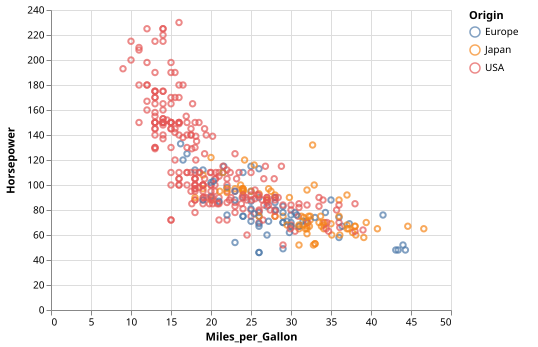

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res4_1: scala.Unit | os.Path = ()

In [4]:
val scatterPlot = VegaPlot.fromResource("scatter.vl.json")
scatterPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.y.field := "Horsepower",
  _.encoding += json""" {"color": { "field": "Origin", "type": "nominal" }} """,
)

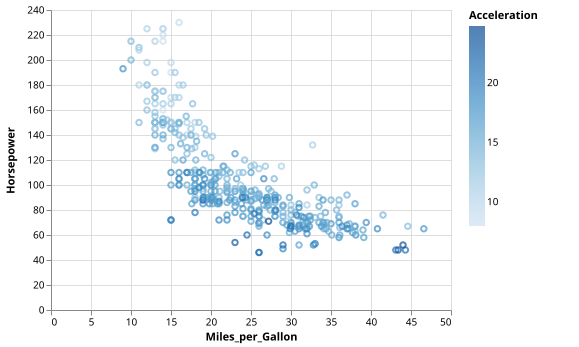

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res5: scala.Unit | os.Path = ()

In [5]:
scatterPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.y.field := "Horsepower",
  _.encoding += (color = (field = "Acceleration", `type` = "quantitative")).asJson,
)

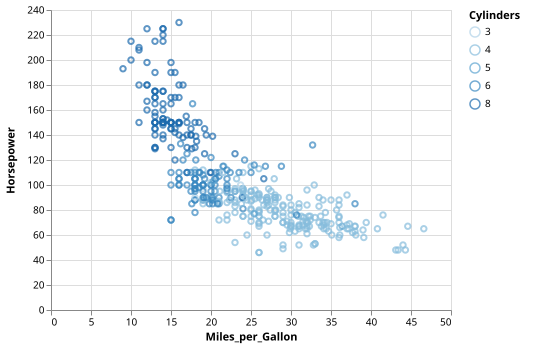

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res6: scala.Unit | os.Path = ()

In [6]:
scatterPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.y.field := "Horsepower",
  _.encoding += json""" {"color": { "field": "Cylinders", "type": "ordinal" }} """,
)

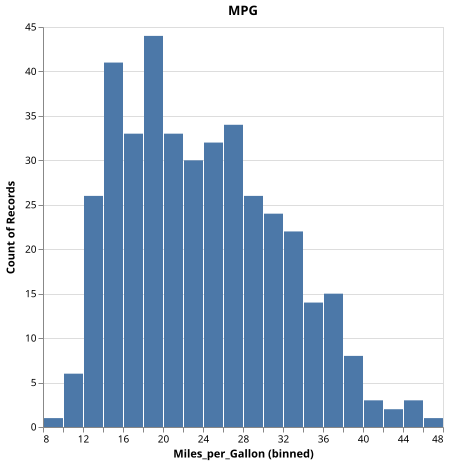

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEySYUqUMSSCGcCGgDaoAIJQocQXABOa9vNQBGAExKAwgE9hs5TYOoADiUAERoIHEEkCwQ4WUw0AGYABgB2JQAJNmsIOBw2AHcbNEdkpQBZGisIAH0cG2qAcR1BOWKgkAA5JBi0EFg4Yms2K0wAAn7SQStR5GEmBkUQAHlrGloHEABVAGUTRYB1ODWsappZasEmfwSAViSAFiUATTgka17HAE4UpP4kxz+jkWLzeAEk4sVvkkAL4KUzmSw2OytJyOSg3dxeM6+bJodqhcKRaKxeKoW5JDJZHJ5QrvJxiDEgCpVWr1JpTFGORldHroeY0KAAa1GEEFXjewoSziSixWazOvR2eyUh2OmFO50u1zEnwSz1edJAXx+gMBwIN4NJxphcJAZgsVlsmHsxUcmO8OP8+LCESiiBJiUc7Uy2VyBSKTju5Uq+lZ1kazU57R5cF6EQ8CDYDHoIrUlmEmFTSjl60VuwORzIJzOFyuiXuCTE+reHyhpv+5rBEKcUNh8IdSOdnNcIE8Hr8eJCPqJ-u7yUeIBD1PDdK5FKZMZqdXj7JaDkcTc63VT6G6UFG1jgTEsIog8WLq1L6CVFbVGtr1wbepAIMN1vbQLNtYlqQj8fZ2gijrIvuSTou62IToEU6En6MRzkkI5LmGtLFPc67MrG24Jhy+5pEevIgAAZlkyijJgWRnGwsqPgqz7liqlbVpqdZkvc9yfEBrYmv8ZpASBPZgba9qIk6LpOOuY4IbiSEgASvrEt29zOAJi5UthEZfO0BFbmyib7tyx69NR1i0RQkQAB40HAox3DKD7yhsL4cW+NZamgDb3G6P4GkJvwiR2Yndta4HSVBQ4ODpik+Ih3ooRppL3DcC5YTSEbONK0YskRu6cguKa9BMQwjKMNAIDgOgoO5T5bOxICqlW6q+TxDZZYJ6D-uFgHBV2Vq9lJkGDnJARwaOWLJcpqXqbOGV4ZSoa5XSzhcoVhGmSRuFKOV6Dppm2YwKMlEMNYHg1TQNDMR5ZbKm1nGddx-gNi4fVGm2g2dsBUVjf2MnQcUClzZ6k6qdOqEBqgmWMjlK5oPljLGXGxF7gd5EniAeRxDQUTjGoOhnI1ywsZ5rXtVxH7+VpjK-qFAH-eJ0XjQOskotNjJJZDKlqTOaGkgknzrkjOE9vhm4YyV5mHZZp4IOe3RMEgEAQEgyhZKMygRA9zVeS9PnvYkARRsNf6-QCEWW2zQMQZzoNOCkM184hC6C7DUUJN+EsGdtG5FXtWOoLIDBTArFFQHQQyxLrED8Ftoz1VM6sG6xIAAKJXWwdSvh175+WSSRi99A020Nv725JwNxXJjhorzEMpchS3C4kFv+6uDI7SZO5mWg4eRzjFXwIMwxwGMEz5s5UByPPV0QKMAAUED5AAlBnVPPTTb10-DjhaeX1uiXbgO147IPxa68HzV6bdC3DtxBd3xQ3N+6PFYPYcR4IUe42srReiqxZBsFXuvLeTVM5Gz3kXbqSQEgLiZv1U+ttq4XxtHXSanJYLN3HAtR+3sRYBD9npDaxQUhoxlt-fav8R5HTxoIDMWYcya0LFMEQEDN7byegXWmxdApiEPCgn6wlK6s0wTFCaXN9xBXdoQ6GaVlqJDEOLchyMXbUODgPOhw9-6jyVueS815BC3jGGvHh0Cd78P3sXBI5t1yiIrmfDBo1L6xRwTBO+-NFpPznKQtay5JaOB+H3WWP9A6MO1soMgc8YDNFiHE6wIoiwU0emxXer14HXBuGIb8zi0FVwtFIjm18po+Nbko9uz9Vq6XWpog80sdGY1KgAtMzDTo5gAORQAYKoUYSC3LpMNtTbJXVtSlxPuI1xJT3FYKvvXbmlTFFe3SokDCQT9KrjqV-EOKJ9HtPQEAmYDA7xIFkGQUYTA2Aa0GRhXhmTbE5MSLcApIVUEzPQXM0CCzPGyLQJ8N2LdVkw3WfDJI6iGkhItns3RocomKz6OPKqU8ZhyELMTawLRHktSySbA+CQUhiCCoUr5xSRq-OkU7G+8kVkP2qf4jKNxEYaMlqjcJtCEVlSRfyIUox9DqExfkJAZA5DcKgSMmBYyCX2KSAEERHyxFhQkZFeZ1LymcnwUpD6RDwWNzIdCiMnxtG7XhSiZwPKKL0Q8GwdQ4wshyCQDMCUt1cUACkkD1XkN5QuEyUZEpHGSlVszKUST+TI52XJgUEP8IeNZKiezBjZca01-dWkOHykcphLCzq6zOYWd41i+G+oETxZwpD3ktk+SG75Yb2bYIBZGGNOq0DxrBYmr4Ok36oG+Jy-Z+5kxIrPKMGAWRZBT1xbA8ZptUDOBSCkZBSqXF1oBuqspSz9yHgUXGvVibpRQuCRGc2-bzWZqCowk5yBSCrCFFOmVfrZ3OBuAEMiwaWZqqpRurxuEW3338nujuvayI9oCEZGhA6UZkWiWoCADBZAp0EDcRwwySyZ09d655-q50lCccuopkj12NudtKP9-NPYdqA32+pR66T3EPHCjNKNDyMOIMMQU69RXxwNY4XWlgGD2WcjkVQPqpUbBzkMfOpa7E8SDLcaZtaKVrq-cR2loSyMe0A3DRuh7tl4jIoxuWKMLIUTqAwOJdqXIPFxRJvOaS4HYecGIFIQb8PksIypxZP6nD3A08pCjyigMoZAymukZcg5mqY3Oq1uMkD9JoKMFDSRRiCAMMW9AtmpPG0fQfS1pRLbMz+p+8NGrN2UL87qxlxCwbZVC4CtNES6HPuzZrJATBRifE+GktD4nc5ZYc0+oljM3OKY8yV79TaXAVYA1V-VW0tkUNRJ-CDZ7mPZqYAgfIowD3OBs31+zM7cvOCQQpj958iNecm9q-9qB22Be051hbmjwuGZ-vNwxIAR1kEvAgbw978U5eLk5+47R31FfO55-5UaFw7qhgmoDjZdOLa2g1rluDs0nMos+1DlMS3ZbLR9Elw3q3KrO24yHka1PXd8Vp9CIWjWbUhaeqLKHs0TBulAaU-2sOzobMS074PyfjdUw3BI02BaUefkGJ77LWcRfTUZ1E2aYlxN1ge7n0mXnwwca5knK6lM1wjTShuPN6Vw8l+hWrDPITLZaYrnSjCYAJZcJC5QGv8cyY+ikKUAvVUQ+F5d6H4uAs1O7NR0D4G7dveg0i1QmA4MIYiMhnHGSQAYYuTz3LuHpmV1DcpiSjhSveejdTzTs3O11J7S9lbUWK1s5RZPMYpAKDbeSCn0ZAOCco2BznsnPyC9F8mzDkFlX4faZKDL1NzPFfNY+zau1zr55DFkOTHrvR0+iYG0duvBXPm59XTXQvE2o2JRHzNsfYfk3W-oQY17TWTOAJoinM49F3db6Bw8RVevvj74NxfI-IuFq4Msa5+FupI4edW8MkekWiuhyH2bGggHGIqcSCGcG241ycAU80wjcKQe2kmB2sqsm3woObmv+Y2xoABgeam34sOt2tOpIx2mEkBSW0+kSDuw6ysow32iAf26WeKmeQO+SS63+KQZBxWFBg+UaNw4ud2oeDBs+PaKGqOkG9I2aJ0rC507C+YXCfSd4bACAb+h29iDYOkZKYh-uEhx+VOMh9BxmSOjSTO8ujWCKMe0cDe1UM8UwzkswNA8whhhB1wUophpBfe9aP+kh1hpeykshTKdhk+dIYGrBdCXwGOT+ICjEVm7e0qnenurymyu+Yi5hQulhgB5kNh5eQGjB8RYMzSMBkSQ6FEI6yA6g2sRaYmeO7+PEUoiRBRFBoR+eJRVBDcI4tBfi1WZIXczBvcThaO+4MWY8AwqKYwtUqcq+uOTymu2GWkUyvRP+-Rh+ERDcTcZuEu92mkjhihVCSR3KahGKhM54UAJM3gzqTAQw5mCSBhfB06AR9M

res7_1: scala.Unit | os.Path = ()

In [7]:
val histogram = VegaPlot.fromResource("histogram.vl.json")
histogram.plot(
  _.title := "MPG",
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.x.bin.step := 2
)

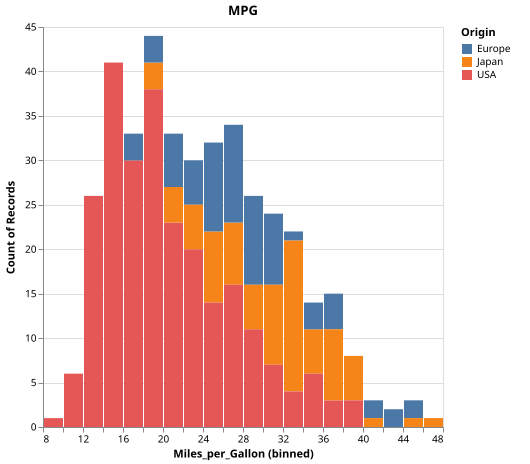

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEySYUqUMSSCGcCGgDaoAIJQocQXABOa9vNQBGAExKAwgE9hs5TYOoADiUAERoIHEEkCwQ4WUw0AGYABgB2JQAJNmsIOBw2AHcbNEdkpQBZGisIAH0cG2qAcR1BOWKgkAA5JBi0EFg4Yms2K0wAAn7SQStR5GEmBkUQAHlrGloHEABVAGUTRYB1ODWsappZasEmfwSAViSAFiUATTgka17HAE4UpP4kxz+jkWLzeAEk4sVvkkAL4KUzmSw2OytJyOSg3dxeM6+bJodqhcKRaKxeKoW5JDJZHJ5QrvJxiDEgCpVWr1JpTFGORldHroeY0KAAa1GEEFXjewoSziSixWazOvR2eyUh2OmFO50u1zEnwSz1edJAXx+gMBwIN4NJxphcJAZgsVlsmHsxUcmO8OP8+LCESiiBJiUc7Uy2VyBSKTju5Uq+lZ1kazU57R5cF6EQ8CDYDHoIrUlmEmFTSjl60VuwORzIJzOFyuiXuCTE+reHyhpv+5rBEKcUNh8IdSOdnNcIE8Hr8eJCPqJ-u7yUeIBD1PDdK5FKZMZqdXj7JaDkcTc63VT6G6UFG1jgTEsIog8WLq1L6CVFbVGtr1wbepAIMN1vbQLNtYlqQj8fZ2gijrIvuSTou62IToEU6En6MRzkkI5LmGtLFPc67MrG24Jhy+5pEevIgAAZlkyijJgWRnGwsqPgqz7liqlbVpqdZkvc9yfEBrYmv8ZpASBPZgba9qIk6LpOOuY4IbiSEgASvrEt29zOAJi5UthEZfO0BFbmyib7tyx69NR1i0RQkQAB40HAox3DKD7yhsL4cW+NZamgDb3G6P4GkJvwiR2Yndta4HSVBQ4ODpik+Ih3ooRppL3DcC5YTSEbONK0YskRu6cguKa9BMQwjKMNAIDgOgoO5T5bOxICqlW6q+TxDZZYJ6D-uFgHBV2Vq9lJkGDnJARwaOWLJcpqXqbOGV4ZSoa5XSzhcoVhGmSRuFKOV6Dppm2YwKMlEMNYHg1TQNDMR5ZbKm1nGddx-gNi4fVGm2g2dsBUVjf2MnQcUClzZ6k6qdOqEBqgmWMjlK5oPljLGXGxF7gd5EniAeRxDQUTjGoOhnI1ywsZ5rXtVxH7+VpjK-qFAH-eJ0XjQOskotNjJJZDKlqTOaGkgknzrkjOE9vhm4YyV5mHZZp4IOe3RMEgEAQEgyhZKMygRA9zVeS9PnvYkARRsNf6-QCEWW2zQMQZzoNOCkM184hC6C7DUUJN+EsGdtG5FXtWOoLIDBTArFFQHQQyxLrED8Ftoz1VM6sG6xIAAKJXWwdSvh175+WSSRi99A020Nv725JwNxXJjhorzEMpchS3C4kFv+6uDI7SZO5mWg4eRzjFXwIMwxwGMEz5s5UByPPV0QKMAAUED5AAlBnVPPTTb10-DjhaeX1uiXbgO147IPxa68HzV6bdC3DtxBd3xQ3N+6PFYPYcR4IUe42srReiqxZBsFXuvLeTVM5Gz3kXbqSQEgLiZv1U+ttq4XxtHXSanJYLN3HAtR+3sRYBD9npDaxQUhoxlt-fav8R5HTxoIDMWYcya0LFMEQEDN7byegXWmxdApiEPCgn6wlK6s0wTFCaXN9xBXdoQ6GaVlqJDEOLchyMXbUODgPOhw9-6jyVueS815BC3jGGvHh0Cd78P3sXBI5t1yiIrmfDBo1L6xRwTBO+-NFpPznKQtay5JaOB+H3WWP9A6MO1soMgc8YDNFiHE6wIoiwU0emxXer14HXBuGIb8zi0FVwtFIjm18po+Nbko9uz9Vq6XWpog80sdGY1KgAtMzDTo5gAORQAYKoUYSC3LpMNtTbJXVtSlxPuI1xJT3FYKvvXbmlTFFe3SokDCQT9KrjqV-EOKJ9HtPQEAmYDA7xIFkGQUYTA2Aa0GRhXhmTbE5MSLcApIVUEzPQXM0CCzPGyLQJ8N2LdVkw3WfDJI6iGkhItns3RocomKz6OPKqU8ZhyELMTawLRHktSySbA+CQUhiCCoUr5xSRq-OkU7G+8kVkP2qf4jKNxEYaMlqjcJtCEVlSRfyIUox9DqExfkJAZA5DcKgSMmBYyCX2KSAEERHyxFhQkZFeZ1LymcnwUpD6RDwWNzIdCiMnxtG7XhSiZwPKKL0Q8GwdQ4wshyCQDMCUt1cUACkkD1XkN5QuEyUZEpHGSlVszKUST+TI52XJgUEP8IeNZKiezBjZca01-dWkOHykcphLCzq6zOYWd41i+G+oETxZwpD3ktk+SG75Yb2bYIBZGGNOq0DxrBYmr4Ok36oG+Jy-Z+5kxIrPKMGAWRZBT1xbA8ZptUDOBSCkZBSqXF1oBuqspSz9yHgUXGvVibpRQuCRGc2-bzWZqCowk5yBSCrCFFOmVfrZ3OBuAEMiwaWZqqpRurxuEW3338nujuvayI9oCEZGhA6UZkWiWoCADBZAp0EDcRwwySyZ09d655-q50lCccuopkj12NudtKP9-NPYdqA32+pR66T3EPHCjNKNDyMOIMMQU69RXxwNY4XWlgGD2WcjkVQPqpUbBzkMfOpa7E8SDLcaZtaKVrq-cR2loSyMe0A3DRuh7tl4jIoxuWKMLIUTqAwOJdqXIPFxRJvOaS4HYecGIFIQb8PksIypxZP6nD3A08pCjyigMoZAymukZcg5mqY3Oq1uMkD9JoKMFDSRRiCAMMW9AtmpPG0fQfS1pRLbMz+p+8NGrN2UL87qxlxCwbZVC4CtNES6HPuzZrJATBRifE+GktD4nc5ZYc0+oljM3OKY8yV79TaXAVYA1V-VW0tkUNRJ-CDZ7mPZqYAgfIowD3OBs31+zM7cvOCQQpj958iNecm9q-9qB22Be051hbmjwuGZ-vNwxIAR1kEvAgbw978U5eLk5+47R31FfO55-5UaFw7qhgmoDjZdOLa2g1rluDs0nMos+1DlMS3ZbLR9Elw3q3KrO24yHka1PXd8Vp9CIWjWbUhaeqLKHs0TBulAaU-2sOzobMS074PyfjdUw3BI02BaUefkGJ77LWcRfTUZ1E2aYlxN1ge7n0mXnwwca5knK6lM1wjTShuPN6Vw8l+hWrDPITLZaYrnSjCYAJZcJC5QGv8cyY+ikKUAvVUQ+F5d6H4uAs1O7NR0D4G7dveg0i1QmA4MIYiMhnHGSQAYYuTz3LuHpmV1DcpiSjhSveejdTzTs3O11J7S9lbUWK1s5RZPMYpAKDbeSCn0ZAOCco2BznsnPyC9F8mzDkFlX4faZKDL1NzPFfNY+zau1zr55DFkOTHrvR0+iYG0duvBXPm59XTXQvE2o2JRHzNsfYfk3W-oQY17TWTOAJoinM49F3db6Bw8RVevvj74NxfI-IuFq4Msa5+FupI4edW8MkekWiuhyH2bGggHGIqcSCGcG241ycAU80wjcKQe2kmB2sqsm3woObmv+Y2xoABgeam34sOt2tOpIx2mEkBSW0+kSDuw6ysow32iAf26WeKmeQO+SS63+KQZBxWFBg+UaNw4ud2oeDBs+PaKGqOkG9I2aJ0rC507C+YXCfSd4bACAb+h29iDYOkZKYh-uEhx+VOMh9BxmSOjSTO8ujWCKMe0cDe1UM8UwzkswNA8whhhB1wUophpBfe9aP+kh1hpeykshTKdhk+dIYGrBdCXwGOT+ICjEVm7e0qnenurymyu+Yi5hQulhgB5kNh5eQGjB8RYMzSMBkSQ6FEI6yA6g2sRaYmeO7+PEUoiRBRFBoR+eJRVBDcI4tBfi1WZIXczBvcThaO+4MWY8AwqKYwtUqcq+uOTymu2GWkUyvRP+-Rh+ERDcTcZuEu92mkjhihVCSR3KahGKhM54UAJM3gzqTAQw5mCSBhfB06AR9M

res8: scala.Unit | os.Path = ()

In [8]:
histogram.plot(
  _.data.values := data.asJson,
  _.title := "MPG",
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.x.bin.step := 2,
  _.encoding += json""" {"color": { "field": "Origin", "type": "nominal" }} """,
)

In [ ]:
histogram.plot(
  _.title := "Faceted Histogram of Miles per Gallon by Origin",
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.x.bin.step := 2,
  _.encoding += json""" {"color": { "field": "Origin"}} """,
  _.encoding += json""" {"column": { "field": "Origin"}} """,
)

-- [E050] Type Error: cmd16.sc:1:26 --------------------------------------------
1 |val res16 = histogram.plot(
  |            ^
  |     method plot in object SetupVegaNotebook does not take more parameters
  |
2 |  _.title := "Faceted Histogram of Miles per Gallon by Origin",
3 |...
8 |)(using viz.PlotTargets)
  |
  | longer explanation available when compiling with `-explain`
Compilation Failed

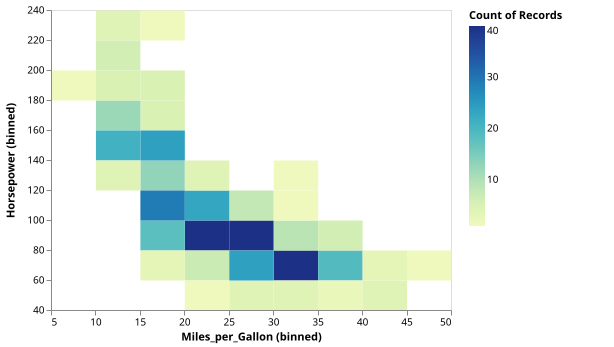

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res10_1: scala.Unit | os.Path = ()

In [10]:
val heatmap = VegaPlot.fromResource("heatmap.vl.json")
heatmap.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.y.field := "Horsepower"
)

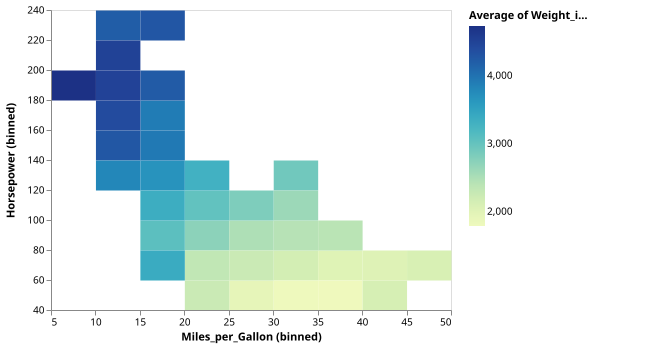

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res11: scala.Unit | os.Path = ()

In [11]:
// os.write.over(os.pwd/"temp.json",
//   heatmap.build(
//     _.data.values := data.asJson,
//     _.encoding.x.field := "Miles_per_Gallon",
//     _.encoding.y.field := "Horsepower",
//     _.encoding.color.aggregate := "average",
//   ).asJson.spaces2
// )

heatmap.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Miles_per_Gallon",
  _.encoding.y.field := "Horsepower",
  _.encoding.color.aggregate := "average",
  _.encoding.color += json"""{"field": "Weight_in_lbs"}""",
)

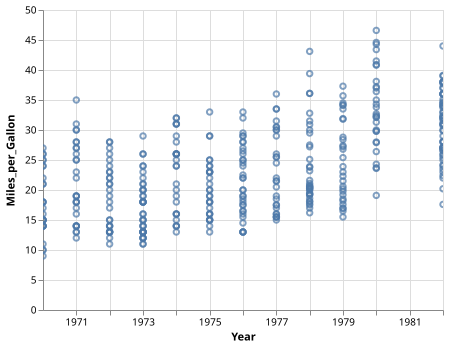

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAFgAY2AacaYsiygAlMiRoRQBmDgF9p3OgENCCvCDQKANqUyUUAbVABBMGEwbMAJyVxoKAIwAmbgGEAnhpJ1Lu5AA5uACJwlAAOGgqmALaYRJJsAOzcghAWlJghENiW9lLcALJw5pQA+iGWxQDimhq2yHb+IAByCtEo4IyYaBYQ5oQABGAdaGbmfZGacABGpCDcAPIWiCRtAKoAyoazINQiCGLFJMUakz4SAKxsLNwAmpgKFm12AJzxbAC0bHYfdlu39wCSsTqLzYciMJjMlmstTsdgAdGcXO5PN4UA0gqFwlEYuJkOcuCBkql0plsnUAGyIkAFIqlcpVDQ1KD2KnNVrIEDTOBgADWfUoPPc9z5EgcbC2CyWzI56023B2okIBygRxOknJTwkNzuDw5z1e32+vx1gNx+tBnHBpnMVmIMLsSI8UC8qTRgWCYQimGiQIk9SSKTSGSyursF3yhR0dIslWqMIabMwbTCrkiFCY-KUIzghCT80WCGWMo2WwVeyVh2OpxYEnJ2vujxBhs+xoBQPNYJAxmtULt0scjpRrr87sxXp9uKkV0JgZJIZZBJpUbKMYZTPsdaaLSTHJaYD6FkwkzM-Mo4nzUtWJflu32lbVeJrWpAf11IHNzZ+9YspvsIM73aQraNj9mwCKDs6qIjiAGKetivpsE4M7EsGZJ2OwEa0iusaMjCiRbuyIAwCkdB9IQKQkBAEoFkWICyqWt4ViqVaSCwLBPN+jYGp8Rrfr+wKvABEI2tCoEQS6Pjoh6WLejirAOBxyFBqSoZPA0S4lNha4wqy25tMRFikQgmgKAAHlgfQXOKF6FtKdHXtsjHKqqPg1iwDovjqXHvDxLZ8e2-6Wl2wm9iBKCKW4ToSW6MHSeOcnICwZzTkSynzsgDhiphy70nG-bTombSDJ03S9H0cCRCEJnUZexZyo5irOSxiXnNOr7eZ+rY-gFglBYBIl9mi4EgJFQ6SaOcGyUCbEEqlc5kg4YbZZpuW4fl3CFRyKZpqQGYwKQFiuOVcBwDVtlXvVZZ3sxD41gOnkNnqTa+V+D3dWagVWkBon2ASo2QcOUljvBuJJVSc2obqmVUhp0Y4eudQFXpW28HAEQDEoExQCoNm0fRN6NferksA4VLtU93FfH5b38R2fUhcBtS+MN-3RdBsEyROkhPLNs6Q3+i6Ritq55SyG3IyAe59C0kwKJQlAKHQKR9HQYRnXjDlXUxLmSL44ZvR1L1dbTn3BT2jP9vELPIgDrkTZzCV2BIz4Qyp9hLdSQtw9p0pkIy4uEWAObdDEKuUG8i19FVjJy+rdkAKIHRAZQMYTN2nGwPOcRTPlU69r4m71X0DWFdTwlSrNQUDk1c3i+uu+ldiUst3ui8gfsaAHO7tCVPSYP0xXDIymADNAkAHZQfQABSUNgACUccXan5ZNbd6FIeT77PXnxs9Raxehfa4lV-b8W+mcHkN2hZzPrDWltx3Xf6SRZEUVAEDT7PC+43Z+MNSvRNWBsAkG1LyOdOr+Q+kXM231Bp1DAhXG2bNq4O19L4F2fM3Z1HiDDL2981ooEfgRbu210yMEzLmRkOYR4z3novOqy9ro60Sk3Tcm8PxG0gX+aB-VD79g8pXQGp8Qbql5ihLBdgcEt3wQjIhm1JaRH3IeY8GhTz9Fod-EAkpzoMIJgA9Out9bsO3rxGme8hLmx+vA4+QjYrAympOdBAZxGN1eNI1aCMPbyKVnQBAI9BjVBiH4iw-I8xaJor-TWTlAF13JM+YxlNTEF3MfTSxcCGiCPGnYmuCUQFiLSmhckgssIeJhEjQipDdrkIAORgFIIoPoeT6H2UutEgxeIimKQSbnJJJoUkHwtjFTJMUOZn0nIhZxBTQwYU9iUkWBD26kH9sQ5+hkxhUGUFABAfRJgQHlo0xCzS-5a1Xqcc48SwFb0SdTZJUD94wJLrUJ41soon2yag0GHBJnzVDPrO+pT+y6UDkMUq-cxi8H8fcGoRyolp2YRIeI5IPLdIgWYu5FjYGlzsH9JBbzRkiMSmccGmD0rQ3cfMzx5Tu5cl5H0HQyhcx9GwAoBA0BP50J-kvPRTDmpSF8Gwy5HCd5cIEvc3hgy6iINecOac+KHHuwwS4skTxcFzPhrUBwVK2jkVcBAZQo9ujYzGMKY6zSABSCgqrMm5drZqDgEUb0FSYm5fT0WpMxTpF5Y0UCbjlbXZ4DQr66hVeS9V0pMpPy2hoVMZCVYbOyJy3R-8eUPgcOgi5j0rk9JdW2N1AyrFhi9bbH1wj5XAkUkG8K+F-kUvjJGhR+5GApCgP3GFrS4V2viPEUBmahW9NzdwsVDMC2bmGcgX1cUCVinyT8tEqqcq1vDR5eRBlSLjGGIsXkbbGG2tTWcXw+EUWcLRYOjFjz8pFrZrKydZaXjfP5n4dSeCAUoAcPhbxShKCkCgFHDQF9rLhNqiAC1Vqd2nNfU7AkR7hUntFWevhr6EE2Ltu8sZVb71YJYJuGtYbX2bnkWgHoPJZ4stDrCP0KszCkFMiPNIihrWAZ0SARO3QU42vA3UdBZMnXXPzq6097rz32CtlK71iVS3+uxRh9KB7Q0+1fUCkhmBSB+L1ZZS4zSWPJzCScmJDhyTxEdb251fGB1wcEwhxGl6oLXvsf6hI0nlXFIXbhjKWrdz1LgH0bFbA+gaF0Im5jSc2PJt3T4TVuQDbgOPbcgT+a4GSOszKiTjtLiOeDfO4WrnSb1oVgoSYfQnhPDCdo2iWmQu6fafaqRUWs2oti+Z+LWKHBJZQ36x2i10sKrk23fT9bJiRGwH0adDhNPBZ0205hmUQHZzqzF-jjWHmWY9mOiddnHZFa68gLOsyXPyYysuiWUsECHkiE6bd7G9PkhYA0aD-b3pxaWxK9CyGRk3trrWGdD7FqZdbgsqTKyOSrr6DAUmAHSuRPbfo5hWGPZ3ZzQ9xb4qC2ieLezd7uSHNKVnRlL5u2sv7YB-IweR0wBigu6FjjNZEWzb7QjwuQ60lYokK1t763fT+mx99gHOHCeHcIj4vxKtp0U8qzDiQvgjNvjp6ZxHdMmvxlZ+j9n4yUokrQpqHrCzFLyMYF5xwHA6Ci8m81Fg8RRS05M7vPNT2C0sCV7ZnJQI71c6wb4J9ar9tvvrYoQgX6f1hH-eay1CgGNi7tZBy38Q873cLnYeDz2zgO5S+2GZlbtvOYJ71hMEtB6gv6MMYyw2pDg4iVyynen9M9uly8GP9Oerx4s896cY7HcfO6679KIb8d-YRjlwHIAdV6oUAa6AONGO0RA6HsDle01R7r7LuPCeC0RVxcl1DBK1JbaIbz3rinVmkRCCQcixuO2psuAK4z0f6sLf1I3hX4acXSraxj53+F083a17IpZncB+EY0MRsyn4j+l+iuDspgP3KMLCPEGNqxhNmfj4PqLdjxgvtbtwvfrbgls+KtinriPakhOnj5l-jCDrkdoon0Cdt6OdoFscibqmnEtXlxKgSKnfsvglknqjmzGtk7ngf3oQWwL9jIjCPhhLJUhmArJQh4IynUmeBAJEKftDryjWF0igTfmZqwU3ijkrtwe3hlPXOrqGHjrvv9u+rniCn3APEMCMCPOMB4NMAoSmmcgpPPmoXLrXmwVihwa9uOrgQpl9m7h7ntm3M8PWsDuRIsO-OpqXkBrQQgZIFIFLkwa4Uvpoewdob4RlBbp3mhEYc+ouvYDnoRFLOMMoErA8DQbCooQ+KKO7i4fNuoe4akc1t4SgmhnXP4Y3M3D3kIetAPnnhYeVJVNVBUVDo4fJJnHUTBg1hoQ-u7Erq0QSuwB0WhDVsYZSvWhkEQGjPuGAJjE6CPpMN0CpowC0A4WFqwFhowRTMwbBjMZgczvMRkecJfAYSyLfHka5i9gPsDsZ

res12: scala.Unit | os.Path = ()

In [12]:
scatterPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Year",
  _.encoding.x.`type` := "temporal",
  _.encoding.y.field := "Miles_per_Gallon"
)

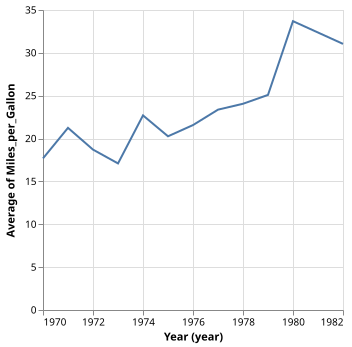

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoAIJgwmNZgBOCuNBQBGAEzcAwgE81JOue3IAHNwAicJQADmpyxgC2mEQSAOzcghBmlJhBENjmtuzcALJwppQA+kHmBQDi6mrWyDa+IABycpEo4IyYaGYQpoQABGCtaCam3eHqcABGpCDcAPJmiCTNAKoAyvpTINQiCGIFJAVqY14sAKxsACzcAJqYcmbNNgCcMWwAtGw2bzbr17cAktHVJ5sGQGIwmcyWKo2GwAOmOTlc7k8KFqAWCoQiUXEyBOXBACSSKTSGWqADZ4SBcvkiiVympKlBbBSGk1kCAJnAwABrbqULmuW48lh2NjrWbzRlslZrbibUSEXZQfaHVikh4sK43O5sx7PT6fb5a-7Y3XAzig4ymCzEKE2BFuKAeJIo-yBEJhTCRAEsGrxRLJVLpbU2U45PJaGlmMoVKG1FmYZohZzhChMXkKQZwQgJmZzBALKWrdZy7YKvYHI5nFikzW3e5A-XvQ1-AGmkEgQyWiE2yX2e1I50+V3oj1e7HsC74-1EoNMvFUiPFKN0hm2Gv1RoJtmNMDdMyYMYmXmUcS5iVLIuyrY7csqnFVjUgH7akCmxtfWtmY22IHtzvg60rF7Ng4X7R1kSHEA0XdTFvTYBwp0JQMSRsM553DQol2jekoTiDdWRAGBEjobpCESEgIDFPMCxAaVi2vMslQrVgzjOB5P3rPV3gNT9v0BZ4-zBK1IWAsCnS8VE3QxT0sRQM47HYxCA2JYMHlqBdMNpGNe2ZTdmiIswSIQdQ5AADywbpTlFM980lWjLw2BjFWVLwqzOO0ny1TjXm4pteNbX9zQ7ITuyAlBFJcB1xJdKCpNHWTkDOY5JwJZTZ2QOwRTDaksJXKFJ3jZo+jaDoum6OBwiCEyqPPQsZUc+VnOYxKTknZ9vPfZsvwCgSgv-YSexRUCQEigcJOHGCZIBVi8VSmcSTsENssXLScN7Aq9LZJMU1INMYFIMxnHKuA4Bq2yL3qksbyYu8qz7Ty6x1BtfI-B7upNQKLQAkTbDxUbwMHSSR1g7EkopObkO1TKKQ0yNsNXaoNoI1IiDgMJegUUYoCUGyaLoq9GtvVz5Ipdqnq4j4-Levi2z6kLAKqbxhv+6LIOg6Sx1YB5ZunSGf3QnLVoRpb8K3EAd26RoxjkShKDkOhEm6OgQjOvGHKuxiXNYbxQzejqXq6mnPuCrsGd7GJmcRAHXImjmEpsFhHwhlTbBF2Hcu0lAyHpbhCrZMAsw6KIlcoF5Fu6Kr6Rl1W7IAUQOiBinowmbqONhuY48mfMp17nyN3qvoGsLqlhCkWYgoHJs5nFded9KbHJZbNOXT3kG9tRfc2loSs6TAemKgZ6UwXpoEgA7KG6AAKShsAAShji7k9LJrbtQhCydfZ6c8NnqzUL0LbTEivbfi71jg8uuUOOR93aFqp287giDJIsi5igCAp5n+fcbs-GGuXomck2AsDal5LOnV-IfQLibb6g1qggTLlbVmlc7bem8E7XmLtqgxBhhhOGeVJQP1FomNQyZUyMHTNmekWZh7TzngvOqS9rpa0Sg3dcG83wG0gT+aB-UD69g8uXQGJ8Qaqh5khLBNgcFN3wa3IhftxbhF3PuQ8ahjw9Dod-EA4pzqMIJgA1O2tdYcK3jxamu9BKmx+vAo+wjYrAymuOdBfoJH12eDIj2a0mSPzFgrOgCBh59AqFEAJZheQ5m0dRX+6snKAJrqSR8JiKZmLzhYumVi4G1CEeNexVcEogPEWlFCpIBYrRbl4xGPiSFkN2hQgA5GAUg8hugFIYfZS6sTDE4hKYpJJ2cUlGjSfvM2MVskxXZqfcc8EXFFODGhDxd9CGkB9sQtkz9hhUEUFABA3QxgQFli0+CbS-4axXkcE4iSwGb2SVTVJUC94wKLlUB4lsorH1yag0GHAZnzWDLrW+5Tha6QIgPUqfdhi8ECbcSoxyYkpxYSwGIpIPJ9IgeY+5ljYHFxsH9JB7yJmiMSsccGmD0rQwWYC-KVS2Qcm5N0LQihszdGwHIBA0BP70J-ovfRzDmrsG8Owq5nDt7cP4g8vhIzqiILeYOScBLHGuwwa4kkDxcGC0pZKOwSMxZkWcBARQI8OjY2GIKY6bSABScgqqMh5ZrZqdhEXryFaY25gyMXpKxVCY4ryxooHXPK6ujxaiX21Kqil8MqiZWpSAba5ClabIyFyvR-9eV3jsOgy5j1rn9NdS2d1wzrEhh9dbP1IiFWAkUiG8KeEAURt7HGLuEtGCJCgH3WFHT4X2piDEUBWbhUDLzTw8V9NC3rjGcgf1cVCUikKb8lEaqyl1pQItaN6yRgDDmNydtTC7VpuON4PCqKuHoqHZip561i2szlVO8tTwfl8x8OpPBniEZ2Dwgo+QhBKCkCgBHNQ59rKRNqiAS11qd1nOXQ7PER6RUnrFWe-hy6EG2Jth8yZ1b71YLOOuWtBDl3rgUWgToXIZ6suDtCH0SsTCkFMsPZI8gbVAd0SAeOHQk62og9UdBpNnU3Nzm609Hrz22AttK31iUy2BpxZh9KB7w14YysCsWxRSABP1ZZc4bTWOJwiacuJdhSQxCdX2l1-HB3waE4hxGl6ILXocYGtgeEq3IAzpSZ9izl3auaHIJpcBug4rYN0NQ2gk0sYTuxlNu6vBaqyHrcBx67mCYLXAqRNnZWSftucGTKqF3NyXYp6Ncs5BjG6A8B4ESdE0W0xFvTXSHXSLi9mtFiWLPJexXYNLqGA32xXUpOdJcb7uY1fh6NYxwjYG6DOuwWnwu6c6SwzKIDM5NYSwJ1rjyrMi3HZO+z9syvZdDaUvLCnesKIlggfc4QHTbo4-p0kZxagwYHe9JLG3JWoRQ+Mm91dqyzofYtXLsiKnSdWYRYi3QYB2FODdyLnHsMiye7ml762JWFrEyWtm338mOYO0ho7QPhZ4gUQPI6YARQw9qywqsSLlv9qR-nYdGTsUsE6193b3pfR9f+yD3DrdoTRr8QEpWM6KfzealWbwxmXx07M8j2mbXYys8x+zqZKVSUoXVPJ1uikFGMD8-YDgdBRedtujEYUtPTM73zW9wtZwld2byQCO9XOsHeCfeq-Lb6BcKG-b+kIAGLVWrkIxyn9qoMW5iDnZ7+cbAIfe969HV6MutnmS79KrnecVPTdG0FvcegDGMpN9ggHKvRI7QYhbBne3S6eFH+nPVY+Wfe5OcdDvPmKtxy5wHL7I1KeaLq-VchDXQBxkxmioHg-gf05lR7vG6+y5j3HwtEU8XpbQ4StSneiGZ9fX3tZ4OggkDIsbiv9rziCpM5H5ra3dSN4V5q3FMqutY6d059X2oHta4qfIruRG1AkZZQCV-W-SXF2UwD7iGGhBiBmzYzmxNy8F1Fn0v3nytx4TvxtxS0fG22T2xAdQQmcwCy-2Fh10bSUW6Au09Gu1CxOTFzTQSWr04hQNFVvyXxSwT0+wnRwOXSh07xxW7w8zJGjVjVqUoUzCZUaRPAgHCBP1TUrBYF6Tn2v3MxYKbzRyVx20d1wNrnf1+nxx73Nhz36DBX7n6EGGHhGDcAmBkKi1YGFAUOQKULl1r1YOxXYJGlXy8A0Pb0Uz+1d3d0XQU0eFXXB1fgog0xLyiW5VhziUdmmUa1v0cMX1ULYPUK4IynNzTxQm+Tcw90CIbQIglhGEUAVjuGoLhVPzvGFDdwjyYLgxUPv1sAQnHRQXQxrl8PrkbhyICL5y839iMLz3KkqmqjKPL1kLkhFHsJryv1W2UOcOSOxVLg4JaMJTQnaJQgax3ypVBxRmIHRjAExgdCHzGA6FU0YEaGsLh2wwYPJlqJa3qIwOZyV2WPLROAvh0KlUG1yJ6OCMM

res13_1: scala.Unit | os.Path = ()

In [13]:
val lineChart = VegaPlot.fromResource("line.vl.json")
lineChart.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "Year",
  _.encoding.x.`type` := "temporal",
  _.encoding.x.`timeUnit` := "year",
  _.encoding.y.field := "Miles_per_Gallon",
  _.encoding.y.aggregate := "average"
)

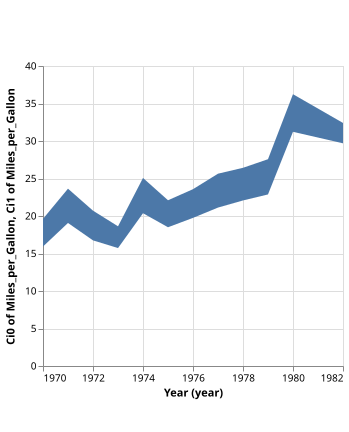

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoAIJgwmNZgBOCuNBQBGAEzcAwgE81JOue3IAHNwAicJQADmpyxgC2mEQSAOzcghBmlJhBENjmtuzcALJwppQA+kHmBQDi6mrWyDa+IABycpEo4IyYaGYQpoQABGCtaCam3eHqcABGpCDcAPJmiCTNAKoAyvpTINQiCGIFJAVqY14sAKxsACzcAJqYcmbNNgCcMWwAtGw2bzbr17cAktHVJ5sGQGIwmcyWKo2GwAOmOTlc7k8KFqAWCoQiUXEyBOXBACSSKTSGWqADZ4SBcvkiiVympKlBbBSGk1kCAJnAwABrbqULmuW48lh2NjrWbzRlslZrbibUSEXZQfaHVikh4sK43O5sx7PT6fb5a-7Y3XAzig4ymCzEKE2BFuKAeJIo-yBEJhTCRAEsGrxRLJVLpbU2U45PJaGlmMoVKG1FmYZohZzhChMXkKQZwQgJmZzBALKWrdZy7YKvYHI5nFikzW3e5A-XvQ1-AGmkEgQyWiE2yX2e1I50+V3oj1e7HsC74-1EoNMvFUiPFKN0hm2Gv1RoJtmNMDdMyYMYmXmUcS5iVLIuyrY7csqnFVjUgH7akCmxtfWtmY22IHtzvg60rF7Ng4X7R1kSHEA0XdTFvTYBwp0JQMSRsM553DQol2jekoTiDdWRAGBEjobpCESEgIDFPMCxAaVi2vMslQrVgzjOB5P3rPV3gNT9v0BZ4-zBK1IWAsCnS8VE3QxT0sRQM47HYxCA2JYMHlqBdMNpGNe2ZTdmiIswSIQdQ5AADywbpTlFM980lWjLw2BjFWVLwqzOO0ny1TjXm4pteNbX9zQ7ITuyAlBFJcB1xJdKCpNHWTkDOY5JwJZTZ2QOwRTDaksJXKFJ3jZo+jaDoum6OBwiCEyqPPQsZUc+VnOYxKTknZ9vPfZsvwCgSgv-YSexRUCQEigcJOHGCZIBVi8VSmcSTsENssXLScN7Aq9LZJMU1INMYFIMxnHKuA4Bq2yL3qksbyYu8qz7Ty6x1BtfI-B7upNQKLQAkTbDxUbwMHSSR1g7EkopObkO1TKKQ0yNsNXaoNoI1IiDgMJegUUYoCUGyaLoq9GtvVz5Ipdqnq4j4-Levi2z6kLAKqbxhv+6LIOg6Sx1YB5ZunSGf3QnLVoRpb8K3EAd26RoxjkShKDkOhEm6OgQjOvGHKuxiXNYbxQzejqXq6mnPuCrsGd7GJmcRAHXImjmEpsFhHwhlTbBF2Hcu0lAyHpbhCrZMAsw6KIlcoF5Fu6Kr6Rl1W7IAUQOiBinowmbqONhuY48mfMp17nyN3qvoGsLqlhCkWYgoHJs5nFded9KbHJZbNOXT3kG9tRfc2loSs6TAemKgZ6UwXpoEgA7KG6AAKShsAAShji7k9LJrbtQhCydfZ6c8NnqzUL0LbTEivbfi71jg8uuUOOR93aFqp287giDJIsi5igCAp5n+fcbs-GGuXomck2AsDal5LOnV-IfQLibb6g1qggTLlbVmlc7bem8E7XmLtqgxBhhhOGeVJQP1FomNQyZUyMHTNmekWZh7TzngvOqS9rpa0Sg3dcG83wG0gT+aB-UD69g8uXQGJ8Qaqh5khLBNgcFN3wa3IhftxbhF3PuQ8ahjw9Dod-EA4pzqMIJgA1O2tdYcK3jxamu9BKmx+vAo+wjYrAymuOdBfoJH12eDIj2a0mSPzFgrOgCBh59AqFEAJZheQ5m0dRX+6snKAJrqSR8JiKZmLzhYumVi4G1CEeNexVcEogPEWlFCpIBYrRbl4xGPiSFkN2hQgA5GAUg8hugFIYfZS6sTDE4hKYpJJ2cUlGjSfvM2MVskxXZqfcc8EXFFODGhDxd9CGkB9sQtkz9hhUEUFABA3QxgQFli0+CbS-4axXkcE4iSwGb2SVTVJUC94wKLlUB4lsorH1yag0GHAZnzWDLrW+5Tha6QIgPUqfdhi8ECbcSoxyYkpxYSwGIpIPJ9IgeY+5ljYHFxsH9JB7yJmiMSsccGmD0rQwWYC-KVS2Qcm5N0LQihszdGwHIBA0BP70J-ovfRzDmrsG8Owq5nDt7cP4g8vhIzqiILeYOScBLHGuwwa4kkDxcGC0pZKOwSMxZkWcBARQI8OjY2GIKY6bSABScgqqMh5ZrZqdhEXryFaY25gyMXpKxVCY4ryxooHXPK6ujxaiX21Kqil8MqiZWpSAba5ClabIyFyvR-9eV3jsOgy5j1rn9NdS2d1wzrEhh9dbP1IiFWAkUiG8KeEAURt7HGLuEtGCJCgH3WFHT4X2piDEUBWbhUDLzTw8V9NC3rjGcgf1cVCUikKb8lEaqyl1pQItaN6yRgDDmNydtTC7VpuON4PCqKuHoqHZip561i2szlVO8tTwfl8x8OpPBniEZ2Dwgo+QhBKCkCgBHNQ59rKRNqiAS11qd1nOXQ7PER6RUnrFWe-hy6EG2Jth8yZ1b71YLOOuWtBDl3rgUWgToXIZ6suDtCH0SsTCkFMsPZI8gbVAd0SAeOHQk62og9UdBpNnU3Nzm609Hrz22AttK31iUy2BpxZh9KB7w14YysCsWxRSABP1ZZc4bTWOJwiacuJdhSQxCdX2l1-HB3waE4hxGl6ILXocYGtgeEq3IAzpSZ9izl3auaHIJpcBug4rYN0NQ2gk0sYTuxlNu6vBaqyHrcBx67mCYLXAqRNnZWSftucGTKqF3NyXYp6Ncs5BjG6A8B4ESdE0W0xFvTXSHXSLi9mtFiWLPJexXYNLqGA32xXUpOdJcb7uY1fh6NYxwjYG6DOuwWnwu6c6SwzKIDM5NYSwJ1rjyrMi3HZO+z9syvZdDaUvLCnesKIlggfc4QHTbo4-p0kZxagwYHe9JLG3JWoRQ+Mm91dqyzofYtXLsiKnSdWYRYi3QYB2FODdyLnHsMiye7ml762JWFrEyWtm338mOYO0ho7QPhZ4gUQPI6YARQw9qywqsSLlv9qR-nYdGTsUsE6193b3pfR9f+yD3DrdoTRr8QEpWM6KfzealWbwxmXx07M8j2mbXYys8x+zqZKVSUoXVPJ1uikFGMD8-YDgdBRedtujEYUtPTM73zW9wtZwld2byQCO9XOsHeCfeq-Lb6BcKG-b+kIAGLVWrkIxyn9qoMW5iDnZ7+cbAIfe969HV6MutnmS79KrnecVPTdG0FvcegDGMpN9ggHKvRI7QYhbBne3S6eFH+nPVY+Wfe5OcdDvPmKtxy5wHL7I1KeaLq-VchDXQBxkxmioHg-gf05lR7vG6+y5j3HwtEU8XpbQ4StSneiGZ9fX3tZ4OggkDIsbiv9rziCpM5H5ra3dSN4V5q3FMqutY6d059X2oHta4qfIruRG1AkZZQCV-W-SXF2UwD7iGGhBiBmzYzmxNy8F1Fn0v3nytx4TvxtxS0fG22T2xAdQQmcwCy-2Fh10bSUW6Au09Gu1CxOTFzTQSWr04hQNFVvyXxSwT0+wnRwOXSh07xxW7w8zJGjVjVqUoUzCZUaRPAgHCBP1TUrBYF6Tn2v3MxYKbzRyVx20d1wNrnf1+nxx73Nhz36DBX7n6EGGHhGDcAmBkKi1YGFAUOQKULl1r1YOxXYJGlXy8A0Pb0Uz+1d3d0XQU0eFXXB1fgog0xLyiW5VhziUdmmUa1v0cMX1ULYPUK4IynNzTxQm+Tcw90CIbQIglhGEUAVjuGoLhVPzvGFDdwjyYLgxUPv1sAQnHRQXQxrl8PrkbhyICL5y839iMLz3KkqmqjKPL1kLkhFHsJryv1W2UOcOSOxVLg4JaMJTQnaJQgax3ypVBxRmIHRjAExgdCHzGA6FU0YEaGsLh2wwYPJlqJa3qIwOZyV2WPLROAvh0KlUG1yJ6OCMM

res14_1: scala.Unit | os.Path = ()

In [14]:
val lineChart = VegaPlot.fromResource("line.vl.json")
lineChart.plot(
  _.data.values := data.asJson,
  _.mark.`type` := "area",
  _.encoding.x.field := "Year",
  _.encoding.x.`type` := "temporal",
  _.encoding.x.`timeUnit` := "year",
  _.encoding.y.field := "Miles_per_Gallon",
  _.encoding.y.aggregate := "ci0",
  _.encoding += json"""{"y2": {"aggregate": "ci1", "field": "Miles_per_Gallon"}}""",
)

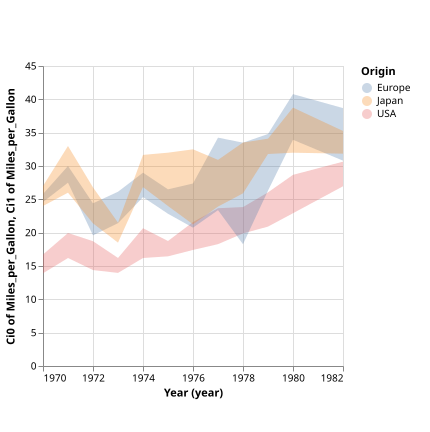

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoAIJgwmNZgBOCuNBQBGAEzcAwgE81JOue3IAHNwAicJQADmpyxgC2mEQSAOzcghBmlJhBENjmtuzcALJwppQA+kHmBQDi6mrWyDa+IABycpEo4IyYaGYQpoQABGCtaCam3eHqcABGpCDcAPJmiCTNAKoAyvpTINQiCGIFJAVqY14sAKxsACzcAJqYcmbNNgCcMWwAtGw2bzbr17cAktHVJ5sGQGIwmcyWKo2GwAOmOTlc7k8KFqAWCoQiUXEyBOXBACSSKTSGWqADZ4SBcvkiiVympKlBbBSGk1kCAJnAwABrbqULmuW48lh2NjrWbzRlslZrbibUSEXZQfaHVikh4sK43O5sx7PT6fb5a-7Y3XAzig4ymCzEKE2BFuKAeJIo-yBEJhTCRAEsGrxRLJVLpbU2U45PJaGlmMoVKG1FmYZohZzhChMXkKQZwQgJmZzBALKWrdZy7YKvYHI5nFikzW3e5A-XvQ1-AGmkEgQyWiE2yX2e1I50+V3oj1e7HsC74-1EoNMvFUiPFKN0hm2Gv1RoJtmNMDdMyYMYmXmUcS5iVLIuyrY7csqnFVjUgH7akCmxtfWtmY22IHtzvg60rF7Ng4X7R1kSHEA0XdTFvTYBwp0JQMSRsM553DQol2jekoTiDdWRAGBEjobpCESEgIDFPMCxAaVi2vMslQrVgzjOB5P3rPV3gNT9v0BZ4-zBK1IWAsCnS8VE3QxT0sRQM47HYxCA2JYMHlqBdMNpGNe2ZTdmiIswSIQdQ5AADywbpTlFM980lWjLw2BjFWVLwqzOO0ny1TjXm4pteNbX9zQ7ITuyAlBFJcB1xJdKCpNHWTkDOY5JwJZTZ2QOwRTDaksJXKFJ3jZo+jaDoum6OBwiCEyqPPQsZUc+VnOYxKTknZ9vPfZsvwCgSgv-YSexRUCQEigcJOHGCZIBVi8VSmcSTsENssXLScN7Aq9LZJMU1INMYFIMxnHKuA4Bq2yL3qksbyYu8qz7Ty6x1BtfI-B7upNQKLQAkTbDxUbwMHSSR1g7EkopObkO1TKKQ0yNsNXaoNoI1IiDgMJegUUYoCUGyaLoq9GtvVz5Ipdqnq4j4-Levi2z6kLAKqbxhv+6LIOg6Sx1YB5ZunSGf3QnLVoRpb8K3EAd26RoxjkShKDkOhEm6OgQjOvGHKuxiXNYbxQzejqXq6mnPuCrsGd7GJmcRAHXImjmEpsFhHwhlTbBF2Hcu0lAyHpbhCrZMAsw6KIlcoF5Fu6Kr6Rl1W7IAUQOiBinowmbqONhuY48mfMp17nyN3qvoGsLqlhCkWYgoHJs5nFded9KbHJZbNOXT3kG9tRfc2loSs6TAemKgZ6UwXpoEgA7KG6AAKShsAAShji7k9LJrbtQhCydfZ6c8NnqzUL0LbTEivbfi71jg8uuUOOR93aFqp287giDJIsi5igCAp5n+fcbs-GGuXomck2AsDal5LOnV-IfQLibb6g1qggTLlbVmlc7bem8E7XmLtqgxBhhhOGeVJQP1FomNQyZUyMHTNmekWZh7TzngvOqS9rpa0Sg3dcG83wG0gT+aB-UD69g8uXQGJ8Qaqh5khLBNgcFN3wa3IhftxbhF3PuQ8ahjw9Dod-EA4pzqMIJgA1O2tdYcK3jxamu9BKmx+vAo+wjYrAymuOdBfoJH12eDIj2a0mSPzFgrOgCBh59AqFEAJZheQ5m0dRX+6snKAJrqSR8JiKZmLzhYumVi4G1CEeNexVcEogPEWlFCpIBYrRbl4xGPiSFkN2hQgA5GAUg8hugFIYfZS6sTDE4hKYpJJ2cUlGjSfvM2MVskxXZqfcc8EXFFODGhDxd9CGkB9sQtkz9hhUEUFABA3QxgQFli0+CbS-4axXkcE4iSwGb2SVTVJUC94wKLlUB4lsorH1yag0GHAZnzWDLrW+5Tha6QIgPUqfdhi8ECbcSoxyYkpxYSwGIpIPJ9IgeY+5ljYHFxsH9JB7yJmiMSsccGmD0rQwWYC-KVS2Qcm5N0LQihszdGwHIBA0BP70J-ovfRzDmrsG8Owq5nDt7cP4g8vhIzqiILeYOScBLHGuwwa4kkDxcGC0pZKOwSMxZkWcBARQI8OjY2GIKY6bSABScgqqMh5ZrZqdhEXryFaY25gyMXpKxVCY4ryxooHXPK6ujxaiX21Kqil8MqiZWpSAba5ClabIyFyvR-9eV3jsOgy5j1rn9NdS2d1wzrEhh9dbP1IiFWAkUiG8KeEAURt7HGLuEtGCJCgH3WFHT4X2piDEUBWbhUDLzTw8V9NC3rjGcgf1cVCUikKb8lEaqyl1pQItaN6yRgDDmNydtTC7VpuON4PCqKuHoqHZip561i2szlVO8tTwfl8x8OpPBniEZ2Dwgo+QhBKCkCgBHNQ59rKRNqiAS11qd1nOXQ7PER6RUnrFWe-hy6EG2Jth8yZ1b71YLOOuWtBDl3rgUWgToXIZ6suDtCH0SsTCkFMsPZI8gbVAd0SAeOHQk62og9UdBpNnU3Nzm609Hrz22AttK31iUy2BpxZh9KB7w14YysCsWxRSABP1ZZc4bTWOJwiacuJdhSQxCdX2l1-HB3waE4hxGl6ILXocYGtgeEq3IAzpSZ9izl3auaHIJpcBug4rYN0NQ2gk0sYTuxlNu6vBaqyHrcBx67mCYLXAqRNnZWSftucGTKqF3NyXYp6Ncs5BjG6A8B4ESdE0W0xFvTXSHXSLi9mtFiWLPJexXYNLqGA32xXUpOdJcb7uY1fh6NYxwjYG6DOuwWnwu6c6SwzKIDM5NYSwJ1rjyrMi3HZO+z9syvZdDaUvLCnesKIlggfc4QHTbo4-p0kZxagwYHe9JLG3JWoRQ+Mm91dqyzofYtXLsiKnSdWYRYi3QYB2FODdyLnHsMiye7ml762JWFrEyWtm338mOYO0ho7QPhZ4gUQPI6YARQw9qywqsSLlv9qR-nYdGTsUsE6193b3pfR9f+yD3DrdoTRr8QEpWM6KfzealWbwxmXx07M8j2mbXYys8x+zqZKVSUoXVPJ1uikFGMD8-YDgdBRedtujEYUtPTM73zW9wtZwld2byQCO9XOsHeCfeq-Lb6BcKG-b+kIAGLVWrkIxyn9qoMW5iDnZ7+cbAIfe969HV6MutnmS79KrnecVPTdG0FvcegDGMpN9ggHKvRI7QYhbBne3S6eFH+nPVY+Wfe5OcdDvPmKtxy5wHL7I1KeaLq-VchDXQBxkxmioHg-gf05lR7vG6+y5j3HwtEU8XpbQ4StSneiGZ9fX3tZ4OggkDIsbiv9rziCpM5H5ra3dSN4V5q3FMqutY6d059X2oHta4qfIruRG1AkZZQCV-W-SXF2UwD7iGGhBiBmzYzmxNy8F1Fn0v3nytx4TvxtxS0fG22T2xAdQQmcwCy-2Fh10bSUW6Au09Gu1CxOTFzTQSWr04hQNFVvyXxSwT0+wnRwOXSh07xxW7w8zJGjVjVqUoUzCZUaRPAgHCBP1TUrBYF6Tn2v3MxYKbzRyVx20d1wNrnf1+nxx73Nhz36DBX7n6EGGHhGDcAmBkKi1YGFAUOQKULl1r1YOxXYJGlXy8A0Pb0Uz+1d3d0XQU0eFXXB1fgog0xLyiW5VhziUdmmUa1v0cMX1ULYPUK4IynNzTxQm+Tcw90CIbQIglhGEUAVjuGoLhVPzvGFDdwjyYLgxUPv1sAQnHRQXQxrl8PrkbhyICL5y839iMLz3KkqmqjKPL1kLkhFHsJryv1W2UOcOSOxVLg4JaMJTQnaJQgax3ypVBxRmIHRjAExgdCHzGA6FU0YEaGsLh2wwYPJlqJa3qIwOZyV2WPLROAvh0KlUG1yJ6OCMM

res15_1: scala.Unit | os.Path = ()

In [15]:
val lineChart = VegaPlot.fromResource("line.vl.json")
lineChart.plot(
  _.data.values := data.asJson,
  _.mark.`type` := "area",
  _.mark += json"""{"opacity": 0.3}""",
  _.encoding.x.field := "Year",
  _.encoding.x.`type` := "temporal",
  _.encoding.x.`timeUnit` := "year",
  _.encoding.y.field := "Miles_per_Gallon",
  _.encoding.y.aggregate := "ci0",
  _.encoding += json"""{"y2": {"aggregate": "ci1", "field": "Miles_per_Gallon"}}""",
  _.encoding += json"""{"color" :{"field": "Origin"}}""",
)